# Etapa 04 — Normalizar a coloração entre lâminas (Reinhard por lâmina)

- Autor: Clésio Gonçalves
- Criado em: 18 nov. 2026

**Objetivo:** igualar a coloração das 8 lâminas, para que o detector não dependa da cor específica de cada lâmina.

| | |
|---|---|
| **Entrada** | `02_datasets_derivados/03_recortes_512_sem_macrofago/` (saída da etapa 03) |
| **Saída** | `02_datasets_derivados/04_recortes_512_sem_macrofago_reinhard/<lamina>/` |
| **Usado em** | exp11 |

**Motivação:** a cor média varia muito entre lâminas, principalmente no canal verde (77 a 121). As lâminas mais claras e acinzentadas (leish_1, leish_4 e leish_8) estão entre as de pior mAP50 em todos os experimentos. CLAHE (exp06) e espaço Lab (exp07) mexeram só no contraste e não igualaram a cor entre lâminas.

**Lógica (Reinhard et al., 2001, aplicado por lâmina):**
1. Converte os pixels para o espaço Lab, ignorando a região mascarada (preto puro).
2. Calcula a média e o desvio de L, a e b de **cada lâmina inteira** (todos os recortes juntos), e não de cada recorte. Assim, um recorte com poucos pixels de fundo não distorce a própria cor.
3. Transforma cada pixel: `(x − média_lâmina) / desvio_lâmina × desvio_ref + média_ref`.
4. A referência é a `leish_7`, a lâmina com melhor mAP50 em todos os experimentos.
5. Devolve a região mascarada como preto puro e copia os `.txt` e o `obj.names` sem alteração.

**Por que não Macenko:** foi testado antes. O modelo de dois corantes, feito para H&E, não descreve bem a coloração Giemsa destas lâminas: a própria lâmina de referência mudava de cor na reconstrução, a ordem dos corantes saiu trocada na leish_9, e a diferença do canal verde entre lâminas quase não diminuiu (passou de 77–121 para 65–108). Com Reinhard por lâmina, ficou entre 61 e 85.

**Ressalva:** as estatísticas de cada lâmina usam só pixels, sem anotações. No uso real isso também é possível, porque a lâmina inteira está disponível antes da detecção.

# Importações e parâmetros

In [1]:
import os
import shutil
import numpy as np
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
diretorio_raiz = Path("/mnt/arquivos/Doutorado")
diretorio_derivados = os.path.join(diretorio_raiz, "02_datasets_derivados")

# Entrada: recortes com o macrófago mascarado de preto (etapa 03)
diretorio_recortes_entrada = os.path.join(diretorio_derivados, "03_recortes_512_sem_macrofago")

# Saída: mesmos recortes com a coloração normalizada
diretorio_recortes_saida = os.path.join(diretorio_derivados, "04_recortes_512_sem_macrofago_reinhard")

extensao = '.png'

# Lâmina usada como referência de cor (melhor mAP50 em todos os experimentos)
lamina_referencia = 'leish_7'

# Usa 1 a cada N pixels válidos de cada recorte para calcular as estatísticas (suficiente e mais rápido)
passo_amostragem = 20

laminas = sorted(d for d in os.listdir(diretorio_recortes_entrada)
                 if os.path.isdir(os.path.join(diretorio_recortes_entrada, d)))
print(laminas)

['leish_1', 'leish_2', 'leish_3', 'leish_4', 'leish_5', 'leish_7', 'leish_8', 'leish_9']


## 1. Funções

In [3]:
# Lê um recorte em RGB
def le_rgb(caminho):
    return cv2.cvtColor(cv2.imread(caminho), cv2.COLOR_BGR2RGB)


# RGB uint8 -> Lab em float (L de 0 a 100; a e b aproximadamente de -127 a 127)
def rgb_para_lab(rgb):
    return cv2.cvtColor(rgb.astype(np.float32) / 255, cv2.COLOR_RGB2LAB)


# Pixels válidos = fora da região mascarada (preto puro)
def mascara_valida(rgb):
    return rgb.max(axis=2) > 0


# Média e desvio de L, a e b de uma lâmina inteira (todos os recortes juntos)
def estatisticas_lamina(lamina):
    pasta = os.path.join(diretorio_recortes_entrada, lamina)
    amostras = []
    for arquivo in sorted(os.listdir(pasta)):
        if arquivo.endswith(extensao):
            rgb = le_rgb(os.path.join(pasta, arquivo))
            amostras.append(rgb_para_lab(rgb)[mascara_valida(rgb)][::passo_amostragem])
    pixels = np.concatenate(amostras)
    return pixels.mean(axis=0), pixels.std(axis=0)


# Aplica a transformação de Reinhard e devolve a região mascarada como preto puro
def normaliza_reinhard(rgb, est_lamina, est_ref):
    media_l, desvio_l = est_lamina
    media_r, desvio_r = est_ref
    lab = (rgb_para_lab(rgb) - media_l) / desvio_l * desvio_r + media_r
    saida = cv2.cvtColor(lab.astype(np.float32), cv2.COLOR_LAB2RGB)
    saida = np.clip(saida * 255, 0, 255).round().astype(np.uint8)
    saida[~mascara_valida(rgb)] = 0
    return saida

## 2. Estatísticas de cor por lâmina

In [4]:
estatisticas = {lamina: estatisticas_lamina(lamina) for lamina in laminas}
for lamina, (media, desvio) in estatisticas.items():
    print(f"{lamina}: L a b médio = {np.round(media, 1)} | desvio = {np.round(desvio, 1)}")
estatistica_referencia = estatisticas[lamina_referencia]

leish_1: L a b médio = [53.7 17.7 -7.8] | desvio = [12.1 12.5  8.2]
leish_2: L a b médio = [ 45.3  38.9 -18.5] | desvio = [10.3 11.9 10. ]
leish_3: L a b médio = [ 45.6  36.4 -16.6] | desvio = [9.5 9.3 8.7]
leish_4: L a b médio = [54.6 15.4 -6.8] | desvio = [10.  10.   7.6]
leish_5: L a b médio = [ 45.8  35.9 -18. ] | desvio = [10.9 11.3 11.5]
leish_7: L a b médio = [ 44.2  37.3 -24.6] | desvio = [11.6 13.3 11.8]
leish_8: L a b médio = [52.2 21.5 -9.6] | desvio = [12.7 13.7  9.5]
leish_9: L a b médio = [ 44.3  39.5 -17.2] | desvio = [10.2 10.6 12.5]


## 3. Gerar os recortes normalizados

In [5]:
if os.path.isdir(diretorio_recortes_saida) and os.listdir(diretorio_recortes_saida):
    print("Os recortes normalizados já foram gerados. Geração ignorada.")
else:
    os.makedirs(diretorio_recortes_saida, exist_ok=True)
    total = 0
    for lamina in laminas:
        pasta_entrada = os.path.join(diretorio_recortes_entrada, lamina)
        pasta_saida = os.path.join(diretorio_recortes_saida, lamina)
        os.makedirs(pasta_saida, exist_ok=True)
        n = 0
        for arquivo in sorted(os.listdir(pasta_entrada)):
            origem = os.path.join(pasta_entrada, arquivo)
            if arquivo.endswith(extensao):
                saida = normaliza_reinhard(le_rgb(origem), estatisticas[lamina], estatistica_referencia)
                cv2.imwrite(os.path.join(pasta_saida, arquivo), cv2.cvtColor(saida, cv2.COLOR_RGB2BGR))
                n += 1
            elif arquivo.endswith('.txt'):
                shutil.copy(origem, pasta_saida)
        print(f"Lâmina '{lamina}': {n} recortes normalizados.")
        total += n
    shutil.copy(os.path.join(diretorio_recortes_entrada, "obj.names"), diretorio_recortes_saida)
    print(f"\nTotal: {total} recortes gerados em '{diretorio_recortes_saida}'.")

Lâmina 'leish_1': 96 recortes normalizados.


Lâmina 'leish_2': 127 recortes normalizados.


Lâmina 'leish_3': 17 recortes normalizados.


Lâmina 'leish_4': 126 recortes normalizados.


Lâmina 'leish_5': 361 recortes normalizados.


Lâmina 'leish_7': 280 recortes normalizados.


Lâmina 'leish_8': 353 recortes normalizados.


Lâmina 'leish_9': 208 recortes normalizados.

Total: 1568 recortes gerados em '/mnt/arquivos/Doutorado/02_datasets_derivados/04_recortes_512_sem_macrofago_reinhard'.


## 4. Verificação: cor média por lâmina antes e depois

In [6]:
def media_rgb(diretorio, lamina, passo=10):
    pasta = os.path.join(diretorio, lamina)
    arquivos = sorted(f for f in os.listdir(pasta) if f.endswith(extensao))[::passo]
    px = []
    for arquivo in arquivos:
        rgb = le_rgb(os.path.join(pasta, arquivo))
        px.append(rgb[mascara_valida(rgb)][::50])
    return np.concatenate(px).mean(axis=0)

for lamina in laminas:
    antes = media_rgb(diretorio_recortes_entrada, lamina)
    depois = media_rgb(diretorio_recortes_saida, lamina)
    print(f"{lamina}: RGB médio antes = {np.round(antes)} | depois = {np.round(depois)}")

leish_1: RGB médio antes = [151. 115. 141.] | depois = [143.  78. 145.]


leish_2: RGB médio antes = [155.  80. 140.] | depois = [144.  79. 147.]
leish_3: RGB médio antes = [157.  82. 138.] | depois = [150.  77. 148.]


leish_4: RGB médio antes = [153. 124. 144.] | depois = [146.  83. 148.]


leish_5: RGB médio antes = [151.  83. 140.] | depois = [144.  77. 146.]


leish_7: RGB médio antes = [144.  77. 147.] | depois = [144.  77. 147.]


leish_8: RGB médio antes = [153. 112. 143.] | depois = [145.  80. 147.]


leish_9: RGB médio antes = [153.  77. 137.] | depois = [144.  79. 149.]


## 5. Verificação visual (linha de cima: original; linha de baixo: normalizado)

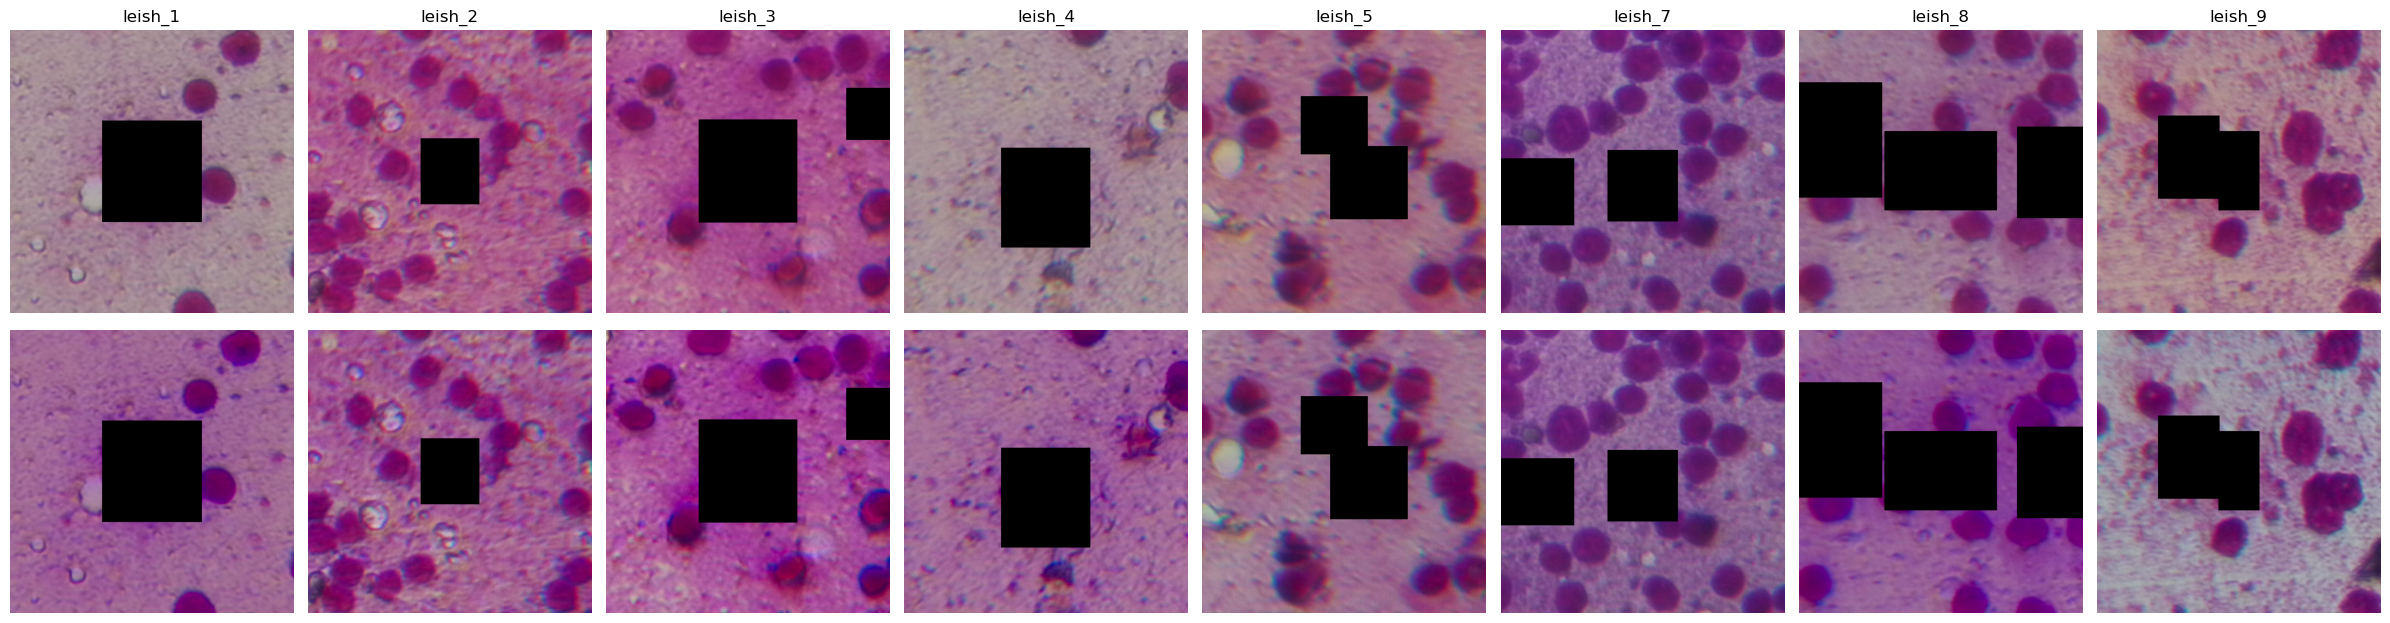

In [7]:
%matplotlib inline
fig, eixos = plt.subplots(2, len(laminas), figsize=(3 * len(laminas), 6.5))
for j, lamina in enumerate(laminas):
    arquivo = sorted(f for f in os.listdir(os.path.join(diretorio_recortes_entrada, lamina)) if f.endswith(extensao))[0]
    eixos[0, j].imshow(le_rgb(os.path.join(diretorio_recortes_entrada, lamina, arquivo)))
    eixos[1, j].imshow(le_rgb(os.path.join(diretorio_recortes_saida, lamina, arquivo)))
    eixos[0, j].set_title(lamina)
    for i in range(2):
        eixos[i, j].axis('off')
plt.tight_layout()
plt.show()